#### Preparing Data

In [1]:
# import the necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import keras

In [2]:
# reading csv data
columns = [
    "capacity",
    "diameter",
    "column_height",
    "porosity",
    "ads_time",
    "C_o",
    "total_LCP",
    "emissions",
    "PFAS_eff",
    "PFAS_ads",
    ]

df1 = pd.read_csv("./training_data/GAC_60k_CORRECTED.csv", usecols=columns)
df = df1.dropna(ignore_index=True)
# df.tail()

In [3]:
# count rows before cleaning
print(f"Number of rows before cleaning: {len(df)}")

Number of rows before cleaning: 60000


In [4]:
epsilon = 1e-20
# cleaning data
df.loc[:, 'PFAS_eff'] = df['PFAS_eff'].clip(lower=0)
df = df[(df['total_LCP'] >= 0)].copy()
df['total_LCP'] = np.log(df['total_LCP'])
df['PFAS_eff'] = np.log(df['PFAS_eff'] + epsilon)

# bounds
print(df.min())
print(df.max())

capacity          1.101685
diameter          0.800136
column_height     1.000066
porosity          0.350000
ads_time          1.007622
C_o               0.010040
total_LCP        11.220578
emissions         0.003025
PFAS_eff        -46.051702
PFAS_ads          0.000005
dtype: float64
capacity         119.997185
diameter           3.999992
column_height      3.999995
porosity           0.499999
ads_time         364.997961
C_o                9.999872
total_LCP         25.115052
emissions          0.833188
PFAS_eff         -10.568922
PFAS_ads          10.189144
dtype: float64


In [5]:
# count rows after cleaning
print(f"Number of rows after cleaning: {len(df)}")

Number of rows after cleaning: 60000


In [6]:
# separate the data into inputs and outputs
inputs = ["capacity", "diameter", "column_height", "porosity", "ads_time", "C_o"]
outputs = [
    "total_LCP",
    "emissions",
    "PFAS_eff",
]
dfin = df[inputs]
dfout = df[outputs]

In [7]:
# define a function to scale the data using min-max scaling
def min_max_scaler(data, data_min, data_max):
    return (data - data_min) /(data_max - data_min)

# define a function to reverse the scaling
def reverse_min_max_scaler(scaled_data, data_min, data_max):
    return scaled_data * (data_max - data_min) + data_min

In [8]:
# scale the data
x_data_min = dfin.min()
x_data_max = dfin.max()
y_data_min = dfout.min()
y_data_max = dfout.max()

x_data_scaled = min_max_scaler(dfin, x_data_min, x_data_max)
y_data_scaled = min_max_scaler(dfout, y_data_min, y_data_max)

x_scaled_min = x_data_scaled.min()
x_scaled_max = x_data_scaled.max()
y_scaled_min = y_data_scaled.min()
y_scaled_max = y_data_scaled.max()


#### Optimise Model with pyomo

In [9]:
import pyomo.environ as pyo
# omlt for interfacing our neural network with pyomo
from Custom_scaling import MinMaxScaling
from omlt import OffsetScaling, OmltBlock
from omlt.io.keras import keras_reader, load_keras_sequential
from omlt.neuralnet import (
    FullSpaceNNFormulation,
    FullSpaceSmoothNNFormulation,
    ReducedSpaceSmoothNNFormulation,
    ReluBigMFormulation,
    ReluComplementarityFormulation,
    ReluPartitionFormulation,
)
from omlt.neuralnet.activations import ComplementarityReLUActivation

In [10]:
# # Check solver availability
# for solver in ["glpk", "cbc", "ipopt", "baron", "cplex", "appsi_maingo", "gurobi"]:
#     print(solver, pyo.SolverFactory(solver).available())

In [11]:
# unscaling back using factors
scaler = MinMaxScaling(
        min_inputs={i: x_data_min[inputs[i]] for i in range(len(inputs))},
        max_inputs={i: x_data_max[inputs[i]] for i in range(len(inputs))},
        min_outputs={i: y_data_min[outputs[i]] for i in range(len(outputs))},
        max_outputs={i: y_data_max[outputs[i]] for i in range(len(outputs))},
    )

# saving unscaled bounds
#input
unscaled_lb = x_data_min[inputs].to_numpy()
unscaled_ub = x_data_max[inputs].to_numpy()
#output
output_lb = y_data_min[outputs].to_numpy()
output_ub = y_data_max[outputs].to_numpy()

# saving scaled bounds
# input
scaled_lb = x_scaled_min[inputs].to_numpy()
scaled_ub = x_scaled_max[inputs].to_numpy()
# output
scaled_output_lb = y_scaled_min[outputs].to_numpy()
scaled_output_ub = y_scaled_max[outputs].to_numpy()

scaled_input_bounds = {i: (scaled_lb[i], scaled_ub[i]) for i in range(len(inputs))}
unscaled_input_bounds = {i: (unscaled_lb[i], unscaled_ub[i]) for i in range(len(inputs))}

In [12]:
# Optimisation Data
obj_scaler = 1e-6
feed_conc_val = 0.5 # ppb
EPA_conc_val = 9.66e-9 # mol/m3
capacity_val = 10 # m3/h
porosity_val = 0.4

# loading saved nn
nn_PFAS_model = keras.models.load_model("GAC_sig_mse(30,30,30)_100k.keras", compile=False)
net = load_keras_sequential(
        nn_PFAS_model, scaling_object=scaler, scaled_input_bounds=scaled_input_bounds, unscaled_input_bounds=unscaled_input_bounds
    )

# Pyomo model with algebraic constraints
def solve_model(objective='cost', eps_emissions=None, feed_conc=feed_conc_val, EPA_conc=EPA_conc_val, capacity=capacity_val, porosity=porosity_val):

    optimization_model = pyo.ConcreteModel()
    
    # Define free variables (Inputs the solver must optimize)
    optimization_model.diameter = pyo.Var(initialize=(unscaled_lb[1]+unscaled_ub[1])/2, bounds=(unscaled_lb[1], unscaled_ub[1]))
    optimization_model.column_height = pyo.Var(initialize=(unscaled_lb[2]+unscaled_ub[2])/2, bounds=(unscaled_lb[2], unscaled_ub[2]))
    optimization_model.porosity = pyo.Var(initialize=(unscaled_lb[3]+unscaled_ub[3])/2, bounds=(unscaled_lb[3], unscaled_ub[3]))
    optimization_model.ads_time = pyo.Var(initialize=(unscaled_lb[4]+unscaled_ub[4])/2, bounds=(unscaled_lb[4], unscaled_ub[4]))
    
    # Output Variables
    optimization_model.total_LCP = pyo.Var(bounds=(output_lb[0], output_ub[0]))
    optimization_model.emissions = pyo.Var(bounds=(output_lb[1], output_ub[1]))
    optimization_model.PFAS_eff_conc = pyo.Var(bounds=(output_lb[2], output_ub[2]))

    # OMLT Block
    optimization_model.nn = OmltBlock()
    formulated_problem = FullSpaceSmoothNNFormulation(net)
    optimization_model.nn.build_formulation(formulated_problem)
    
    # Fix the known inputs directly to shrink the problem size
    optimization_model.nn.inputs[0].fix(capacity)
    optimization_model.nn.inputs[5].fix(feed_conc)

    # Link only the free variables
    optimization_model.con_in_d = pyo.Constraint(expr= optimization_model.diameter == optimization_model.nn.inputs[1])
    optimization_model.con_in_H = pyo.Constraint(expr= optimization_model.column_height == optimization_model.nn.inputs[2])
    optimization_model.con_in_p = pyo.Constraint(expr= optimization_model.porosity == optimization_model.nn.inputs[3])
    optimization_model.con_in_t = pyo.Constraint(expr= optimization_model.ads_time == optimization_model.nn.inputs[4])

    # Link the outputs
    optimization_model.con_out_LCP = pyo.Constraint(expr= optimization_model.total_LCP == optimization_model.nn.outputs[0])
    optimization_model.con_out_emi = pyo.Constraint(expr= optimization_model.emissions == optimization_model.nn.outputs[1])
    optimization_model.con_out_eff = pyo.Constraint(expr= optimization_model.PFAS_eff_conc == optimization_model.nn.outputs[2])

    # Performance Constraints
    optimization_model.epa_limit = pyo.Constraint(expr= optimization_model.PFAS_eff_conc <= pyo.log(EPA_conc + epsilon))
    
    if eps_emissions is not None:
        optimization_model.emissions_con = pyo.Constraint(expr= optimization_model.emissions <= eps_emissions)
    
    # Objective
    if objective == 'cost':
        optimization_model.obj = pyo.Objective(expr= optimization_model.total_LCP, sense=pyo.minimize)
    else:
        optimization_model.obj = pyo.Objective(expr= optimization_model.emissions, sense=pyo.minimize)

    # BARON Configurations
    options = {
    'MaxTime': 3600,   # Maximum time in seconds
    'epsr': 0.05,      # relative gap (percentage fraction)
    'epsa': 1e-4,      # Absolute precision
    'threads': 4,     # No of worker threads for parallel processing     
    'prlevel': 1,      # 1 = Print normal logs, 0 = silent      
    'dolocal': 1       # 1 = Use local search heuristics to speed up finding bounds     
    }
    
    solver = pyo.SolverFactory('baron') 
    results = solver.solve(optimization_model, tee=True, options=options)

    print("# of variables: ", optimization_model.nvariables())
    print("# of constraints: ", optimization_model.nconstraints())

    term_cond = str(results.solver.termination_condition)
    
    # Silently check if the objective has a value
    obj_val = pyo.value(optimization_model.obj, exception=False)
    solution_found = (obj_val is not None)

    if term_cond == 'optimal':
        print("Success: Global optimal solution found")
        status = "Optimal"
    elif term_cond == 'maxTimeLimit' and solution_found:
        print(f"Success: Time limit hit. Feasible solution found (Objective: {obj_val:.4f}).")
        status = "Feasible (Time Limit)"
    else:
        print(f"Solver stopped ('{term_cond}') and NO feasible solution was found.")
        status = "Infeasible"

    def get_val(var):
        # Silently check each variable, return NaN if empty
        v = pyo.value(var, exception=False)
        return v if v is not None else np.nan

    return (capacity,
            get_val(optimization_model.diameter),
            get_val(optimization_model.column_height),
            get_val(optimization_model.porosity),
            get_val(optimization_model.ads_time),
            feed_conc,
            np.exp(get_val(optimization_model.total_LCP)),
            get_val(optimization_model.emissions),
            np.exp(get_val(optimization_model.PFAS_eff_conc) - epsilon),
            status)


Solving for feed concentration: 0.0100 ppb
 BARON version 25.11.28. Built: WIN-64 2025-11-28 09:23:24           
 Running on machine CHE-RES-CUSTOM7

 BARON is a product of The Optimization Firm.
 For information on BARON, see https://minlp.com/about-baron
 Licensee: Hubert Treve at University of Florida, huberttreve@ufl.edu.

 If you publish work using this software, please cite publications from
 https://minlp.com/baron-publications, such as: 

 Zhang, Y. and N. V. Sahinidis, Solving continuous and discrete
 nonlinear programs with BARON, Comput Optim Appl (2024). 
 https://doi.org/10.1007/s10589-024-00633-0
 This BARON run may utilize the following subsolver(s)
 For LP/MIP/QP: CLP/CBC, ILOG CPLEX                             
 For NLP: IPOPT, FILTERSQP
 Doing local search
 Unable to find/load CPLEX library cplex2212.dll.
 Using CPLEX library cplex2211.dll.
 Preprocessing found feasible solution with value 19.6017
 Solving bounding LP
 Starting multi-start local search
 Done with loc

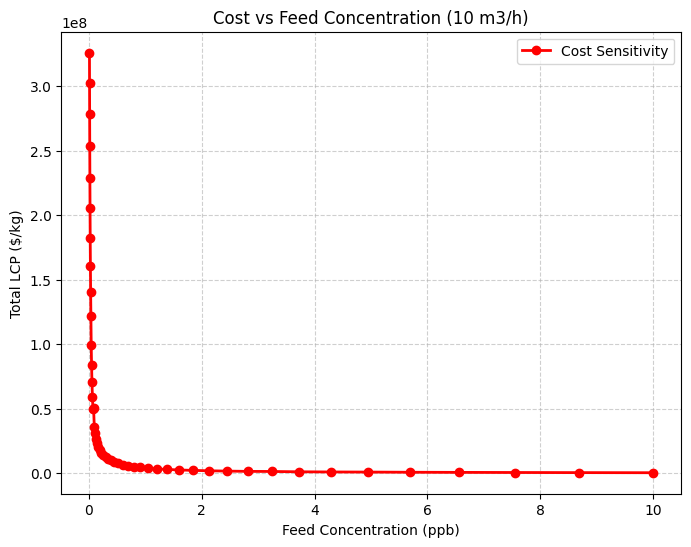


Sensitivity Analysis Optimal Solutions:
Cap.  | Diam. | Height| Por.  | Time  | C_o   | Cost ($/kg) | Emi. (kg) | PFAS Eff. | Status
--------------------------------------------------------------------------------------------------------------
10.000 | 0.800 | 1.000 | 0.350 | 19.111 | 0.0100 | 325785549.23 | 0.0171 | 0.0000 | Feasible (Time Limit)
10.000 | 0.800 | 1.000 | 0.350 | 19.035 | 0.0116 | 302155695.36 | 0.0171 | 0.0000 | Feasible (Time Limit)
10.000 | 0.800 | 1.000 | 0.350 | 18.945 | 0.0133 | 277931415.42 | 0.0171 | 0.0000 | Feasible (Time Limit)
10.000 | 0.800 | 1.000 | 0.350 | 18.836 | 0.0153 | 253442022.36 | 0.0172 | 0.0000 | Feasible (Time Limit)
10.000 | 0.800 | 1.000 | 0.350 | 18.701 | 0.0176 | 229054596.91 | 0.0172 | 0.0000 | Feasible (Time Limit)
10.000 | 0.800 | 1.000 | 0.350 | 18.533 | 0.0203 | 205155631.53 | 0.0172 | 0.0000 | Feasible (Time Limit)
10.000 | 0.800 | 1.000 | 0.350 | 18.317 | 0.0234 | 182127657.41 | 0.0173 | 0.0000 | Feasible (Time Limit)
10.000 | 0.80

In [13]:
# Sensitivity Analysis on Feed Concentration
conc_lb = x_data_min[inputs[inputs.index("C_o")]]
conc_ub = x_data_max[inputs[inputs.index("C_o")]]

# Use geometric spacing to cluster points at the low end where cost is highly sensitive
feed_conc_range = np.geomspace(conc_lb, conc_ub, 50) 

sens_points = []
sens_solutions = []

for fc in feed_conc_range:
    print(f"\nSolving for feed concentration: {fc:.4f} ppb")
    
    # Call the solver
    result = solve_model(objective='cost', feed_conc=fc)
    
    if result is not None:
        # Unpack all 10 variables, including the 'status' string
        Q, d, L, p, t, c_o, cost, emi, eff_con, status = result
        
        # Only save and plot if BARON found a valid numeric cost
        if not np.isnan(cost):
            sens_points.append((fc, cost))
            sens_solutions.append((Q, d, L, p, t, c_o, cost, emi, eff_con, status))
        else:
            print(f"No valid solution found for C_o: {fc:.4f} ppb")

# Save results to Excel
if sens_solutions:
    df_sens = pd.DataFrame(sens_solutions, columns=['capacity', 'diameter', 'column_height', 'porosity', 'ads_time', 'C_o', 'total_LCP ($/kg)', 'emissions (kg)', 'PFAS_eff_con', 'Status'])
    excel_filename = f'sensitivity_results_Co_{capacity_val}m3h.xlsx'
    df_sens.to_excel(excel_filename, index=False)
    print(f"\nSensitivity results saved to '{excel_filename}'")

# Plot Sensitivity Curve
if sens_points:
    fc_vals, cost_vals = zip(*sens_points)
    plt.figure(figsize=(8, 6))
    plt.plot(fc_vals, cost_vals, 'r-o', linewidth=2, label='Cost Sensitivity')
    plt.xlabel('Feed Concentration (ppb)')
    plt.ylabel('Total LCP ($/kg)')
    plt.title(f'Cost vs Feed Concentration ({capacity_val} m3/h)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plot_filename = f'sensitivity_plot_Co_{capacity_val}m3h.png'
    plt.savefig(plot_filename)
    plt.show()

    print("\nSensitivity Analysis Optimal Solutions:")
    print('Cap.  | Diam. | Height| Por.  | Time  | C_o   | Cost ($/kg) | Emi. (kg) | PFAS Eff. | Status')
    print("-" * 110)
    for sol in sens_solutions:
        Q, d, L, p, t, c_o, cost, emi, eff_con, status = sol
        print(f"{Q:.3f} | {d:.3f} | {L:.3f} | {p:.3f} | {t:.3f} | {c_o:.4f} | {cost:.2f} | {emi:.4f} | {eff_con:.4f} | {status}")
else:
    print("No feasible solutions found for Sensitivity Analysis.")